# Proyecto 2: Sistema Multi-Agente ReAct

Flujo completo en Colab (GPU T4) con **arquitectura hexagonal**: el notebook solo conecta adaptadores reales con el núcleo de `src/`.

- **Agentes (LangGraph):** Investigador (bucle ReAct *Thought → Action → Observation*), Auditor de Hechos (guardrail que rechaza y devuelve el flujo) y Redactor.
- **Herramientas:** `kb` (ChromaDB sobre WikiQA), `web` (DuckDuckGo), `calc` (GSM8K) y `python` (MBPP, en un proceso aislado con tiempo límite).
- **Concurrencia:** `kb` y `web` se consultan en paralelo (fan-out de LangGraph) antes del bucle ReAct.
- **Orquestador:** Qwen2.5-7B-Instruct cuantizado a 4 bits corriendo en la T4 (la primera corrida usó Mistral-7B-Instruct-v0.3).
- **Evaluación:** 50 consultas (20 WikiQA + 15 GSM8K + 15 MBPP) contra un Naive RAG de un solo paso, con *Faithfulness* y *Answer Relevance* (LLM-as-a-Judge, con un juez independiente) y verificación objetiva en GSM8K y MBPP.

El código se toma de `/content/Multi-Agent-ReAct` si ya fue subido (por ejemplo con `colab upload`); si no, se clona de GitHub.

## 1. GPU

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Dependencias

In [ ]:
!pip install -q langgraph chromadb ddgs datasets bitsandbytes accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


## 3. Código del proyecto

In [ ]:
import os, sys, subprocess

REPO_URL = "https://github.com/RenzoFelixAponte/Multi-Agent-ReAct.git"
for candidate in ("/content/Multi-Agent-ReAct", os.path.abspath(".."), os.getcwd()):
    if os.path.isdir(os.path.join(candidate, "src", "application")):
        PROJ = candidate
        break
else:
    PROJ = "/content/Multi-Agent-ReAct"
    subprocess.run(["git", "clone", "-q", REPO_URL, PROJ], check=True)
sys.path.insert(0, f"{PROJ}/src")
print("Código del proyecto en:", PROJ)

Código del proyecto en: /content/Multi-Agent-ReAct


## 4. Configuración y adaptadores reales

Cada valor se puede cambiar aquí o con una variable de entorno (`colab exec --env`, que usa `scripts/colab_run.sh`).

- `MODEL_ID`: orquestador local de 4 bits en la T4, lo que pide el enunciado. Por defecto `Qwen/Qwen2.5-7B-Instruct`. La primera corrida usó `mistralai/Mistral-7B-Instruct-v0.3`, que es restringido: hay que aceptar sus términos en Hugging Face y definir `HF_TOKEN`.
- `BACKEND`: `"local"` carga `MODEL_ID` en la GPU; `"nvidia"` usa una API remota, solo para desarrollo sin GPU.
- `JUDGE_BACKEND`: `"nvidia"` (por defecto) usa un modelo remoto grande como juez independiente; `"same"` usa el mismo modelo que orquesta. **Elección documentada:** en la primera corrida el juez era el mismo Mistral de 7B, que puntuaba igual las respuestas correctas y las incorrectas, y juzgaba sus propias respuestas. El enunciado exige que el orquestador sea local, no el juez.
- `RUN_NAME`: carpeta de `results/` donde queda la corrida. Cada modelo tiene la suya, así una corrida nueva no se salta las consultas que ya hizo otra.
- Secretos: `NVIDIA_API_KEY` para el juez y, si el modelo es restringido, `HF_TOKEN`. En Colab van en el panel 🔑 *Secrets*; con la CLI se pasan con `colab exec --env`.

In [ ]:
import os
from adapters.duckduckgo_search import DuckDuckGoSearch
from adapters.chroma_kb import ChromaKB
from adapters.subprocess_code_runner import SubprocessCodeRunner

MODEL_ID = os.environ.get("MODEL_ID", "Qwen/Qwen2.5-7B-Instruct")
BACKEND = os.environ.get("BACKEND", "local")               # "local" (4 bits en la T4) | "nvidia" (remoto)
JUDGE_BACKEND = os.environ.get("JUDGE_BACKEND", "nvidia")  # "nvidia" (juez independiente) | "same"
RUN_NAME = os.environ.get("RUN_NAME", MODEL_ID.split("/")[-1].lower())
FULL_RUN = os.environ.get("FULL_RUN", "1") == "1"          # 0 = solo la prueba de tiempo

try:  # secretos del panel de Colab; fuera de Colab se usa el .env o las variables de entorno
    from google.colab import userdata
    for name in ("HF_TOKEN", "NVIDIA_API_KEY"):
        try:
            os.environ.setdefault(name, userdata.get(name))
        except Exception:
            pass
except ImportError:
    pass

if BACKEND == "nvidia":
    from adapters.nvidia_llm import NvidiaLLM
    llm = NvidiaLLM()
else:
    from adapters.local_llm import LocalLLM
    llm = LocalLLM(MODEL_ID)

if JUDGE_BACKEND == "nvidia":
    from adapters.nvidia_llm import NvidiaLLM
    judge_llm = NvidiaLLM()
else:
    judge_llm = llm

print("Orquestador:", getattr(llm, "model", "local"))
print("Juez:", getattr(judge_llm, "model", "local"))
print("Corrida:", RUN_NAME)

web = DuckDuckGoSearch()
kb = ChromaKB(path="/content/chroma_db" if os.path.isdir("/content") else "./chroma_db")
runner = SubprocessCodeRunner()

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Orquestador: Qwen/Qwen2.5-7B-Instruct (4 bits)
Juez: nvidia/nemotron-3.5-super-vl-120b-a12b
Corrida: qwen2.5-7b-instruct


## 5. Indexar WikiQA en ChromaDB

Se indexan **todas** las frases candidatas de cada pregunta, también las incorrectas (`label=0`). Así la base tiene distractores y el Naive RAG no parte con la respuesta servida en bandeja.

In [ ]:
from adapters.hf_dataset_adapter import HFDatasetAdapter
from adapters.hf_mappers import wikiqa_documents

datasets = HFDatasetAdapter()
wiki = datasets.load("wiki_qa", "validation", limit=300)   # 126 preguntas con respuesta correcta
documents = wikiqa_documents(wiki)
kb.index(documents)
print(f"{len(wiki)} consultas, {len(documents)} frases indexadas (correctas y distractoras)")

README.md:   0%|          | 0.00/13.8k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  594kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  264kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.00MB            

... (44 outputs left out)

/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz:  95%|█████████▍| 75.0M/79.3M [00:08<00:00, 10.6MiB/s]

/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz:  97%|█████████▋| 77.3M/79.3M [00:08<00:00, 10.8MiB/s]

/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:09<00:00, 9.23MiB/s]

126 consultas, 1119 frases indexadas (correctas y distractoras)


## 6. Grafo de agentes

Un grafo por tipo de tarea (`task`), con sus herramientas, su ejemplo resuelto en el prompt y sus reglas de auditoría y redacción:

- **WikiQA (`qa`):** `kb || web` en paralelo → Investigador con `kb` y `web` → Auditor (LLM) → Redactor.
- **GSM8K (`math`):** Investigador con `calc` → Auditor (LLM) → Redactor.
- **MBPP (`code`):** Investigador con `python` (ejecución aislada) → Auditor que **ejecuta** el código entregado con los `assert` del enunciado → el código aprobado se entrega sin reescribir.

En GSM8K y MBPP no se ofrece la web: no aporta y podría devolver la solución publicada del propio benchmark.

Si el Auditor rechaza, el flujo vuelve al Investigador con el motivo y su respuesta rechazada (hasta `max_rounds`). MBPP admite 5 rondas y los demás 3: en MBPP el Auditor ejecuta las pruebas, así que reintentar no puede dejar pasar código erróneo. En WikiQA y GSM8K el Auditor es un LLM, y cada ronda extra es otra oportunidad de aprobar un error.


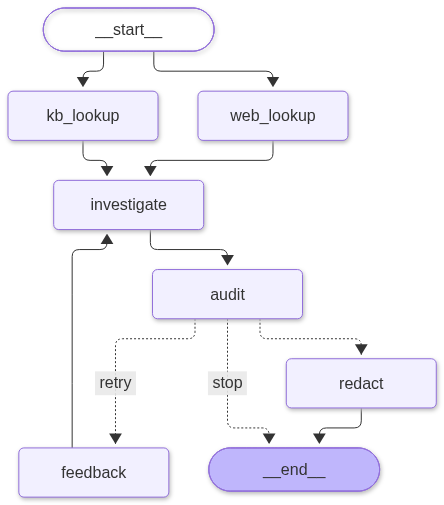

In [ ]:
from IPython.display import Image, display
from application.graph import build_flow

# En la primera corrida, 5 de las 8 abstenciones fueron de MBPP, donde el Auditor verifica ejecutando.
MAX_ROUNDS = {"wiki_qa": 3, "gsm8k": 3, "mbpp": 5}
flows = {
    "wiki_qa": build_flow(llm, web, kb, max_rounds=MAX_ROUNDS["wiki_qa"], prefetch=True, task="qa"),
    "gsm8k": build_flow(llm, web, kb, max_rounds=MAX_ROUNDS["gsm8k"], task="math"),
    "mbpp": build_flow(llm, web, kb, max_rounds=MAX_ROUNDS["mbpp"], runner=runner, task="code"),
}
try:
    display(Image(flows["wiki_qa"].get_graph().draw_mermaid_png()))
except Exception as e:  # draw_mermaid_png necesita acceso a mermaid.ink
    print("Diagrama PNG no disponible:", e)
    print(flows["wiki_qa"].get_graph().draw_mermaid())


## 7. Una consulta con el flujo completo

La traza muestra el bucle ReAct: el modelo escribe cada `Thought` y cada `Action`, y el sistema escribe cada `Observation` con el resultado de la herramienta.

In [ ]:
item = wiki[0]
state = flows["wiki_qa"].invoke({"question": item.question})
print("Pregunta:", item.question)
print("Rondas:", state["rounds"], "| aprobado:", state["verdict"].approved)
print("Evidencia:", [(e.source, e.text[:60]) for e in state["report"].evidence])
print("Rechazos del Auditor:", state.get("rejections") or "ninguno")
print("Respuesta:", state.get("final", "[sin respuesta aprobada]"))
print("\nTraza ReAct de la última ronda:\n" + state["report"].trace)

Pregunta: how big is bmc software in houston, tx
Rondas: 1 | aprobado: True
Evidencia: [('BMC Software', 'Headquartered in Houston , Texas , BMC develops, markets and'), ('BMC Software', 'BMC Software, Inc. is an American company specializing in Bu'), ('BMC Software', 'Employing over 6,000, BMC is often credited with pioneering '), ('https://en.wikipedia.org/wiki/BMC_Software', 'In October 2024, BMC announced that it was splitting into tw'), ('https://rocketreach.co/bmc-software-profile_b5c61feff42e0c48', 'BMC Software is an IT Services and IT Consulting, Software D'), ('https://www.bmc.com/support/resources/vendor-fact-sheet.html', 'BMC helps customers run and reinvent their businesses with o')]
Rechazos del Auditor: ninguno
Respuesta: BMC Software in Houston, TX has an employee base of over 6,000 people.

Traza ReAct de la última ronda:
Observation (recuperación inicial de kb y web, hecha en paralelo): [BMC Software] Headquartered in Houston , Texas , BMC develops, markets and sells 

## 8. Prueba de tiempo

Antes de lanzar las 50 consultas se miden unas pocas (1 de cada dataset, con ambos métodos) y se extrapola el tiempo total.

In [ ]:
import time
from adapters.jsonl_result_store import JsonlResultStore
from application.eval_set import EVAL_MIX, build_eval_set
from application.eval_summary import latest
from application.evaluator import Evaluator
from application.judge import Judge

RESULTS_DIR = os.path.join("/content/results" if os.path.isdir("/content") else os.path.join(PROJ, "results"),
                           RUN_NAME)


def make_evaluator(filename):
    store = JsonlResultStore(os.path.join(RESULTS_DIR, filename))
    return Evaluator(flows, llm, kb, Judge(judge_llm), store, runner), store


def show(r):
    print(f"[{r.dataset:7}] {r.item_id:>6} {r.method:12} respondida={r.answered!s:5} "
          f"faith={r.faithfulness} rel={r.relevance} correcta={r.correct} {r.seconds:6.1f}s {r.error}")


smoke_set = build_eval_set(datasets, tuple((n, s, 1) for n, s, _ in EVAL_MIX))
smoke_eval, smoke_store = make_evaluator("prueba_tiempo.jsonl")
smoke_eval.run(smoke_set, on_record=show)

smoke = latest(smoke_store.load())
per_record = sum(r.seconds for r in smoke) / len(smoke)
total = sum(c for _, _, c in EVAL_MIX) * 2 * per_record
print(f"\n~{per_record:.0f} s por registro -> estimado para {sum(c for _, _, c in EVAL_MIX)} consultas x 2 métodos: {total / 60:.0f} min")

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

... (11 outputs left out)

Generating test split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/90 [00:00<?, ? examples/s]

Generating prompt split:   0%|          | 0/10 [00:00<?, ? examples/s]


~40 s por registro -> estimado para 50 consultas x 2 métodos: 67 min


## 9. Evaluación sobre 50 consultas

Cada resultado se guarda en `results/<RUN_NAME>/evaluacion.jsonl` apenas se calcula, con la evidencia, la traza y los motivos de rechazo. Si la celda se interrumpe, **volver a ejecutarla reanuda** donde quedó (salta lo hecho y reintenta lo que falló). Si el juez remoto falla, la respuesta se conserva sin puntaje y `scripts/rejuzgar.py` la juzga después, sin volver a generarla.

In [ ]:
eval_set = build_eval_set(datasets)
print(len(eval_set), "consultas:", {d: sum(i.dataset == d for i in eval_set) for d in ("wiki_qa", "gsm8k", "mbpp")})
evaluator, store = make_evaluator("evaluacion.jsonl")
if FULL_RUN:
    evaluator.run(eval_set, on_record=show)
else:
    print("FULL_RUN=0: se omite la corrida completa")

50 consultas: {'wiki_qa': 20, 'gsm8k': 15, 'mbpp': 15}


[wiki_qa]    Q11 multiagente  respondida=True  faith=1.0 rel=1.0 correcta=None   19.6s 


[wiki_qa]    Q11 naive_rag    respondida=True  faith=0.5714285714285714 rel=0.5 correcta=None   15.2s 


[wiki_qa]    Q48 multiagente  respondida=True  faith=0.0 rel=1.0 correcta=None  109.7s 


[wiki_qa]    Q48 naive_rag    respondida=True  faith=1.0 rel=1.0 correcta=None   10.7s 


[wiki_qa]    Q66 multiagente  respondida=True  faith=0.875 rel=1.0 correcta=None   29.6s 


... (91 outputs left out)

[mbpp   ]     24 multiagente  respondida=True  faith=1.0 rel=1.0 correcta=True   26.2s 


[mbpp   ]     24 naive_rag    respondida=True  faith=0.2 rel=1.0 correcta=True   23.0s 


[mbpp   ]     25 multiagente  respondida=True  faith=1.0 rel=1.0 correcta=True   28.2s 


[mbpp   ]     25 naive_rag    respondida=True  faith=0.5 rel=1.0 correcta=True   14.5s 


## 10. Tabla comparativa: multi-agente vs Naive RAG

- `faithfulness` y `answer_relevance`: promedio de 0 a 1 que da el juez. Una **abstención** (el Auditor nunca aprobó) puntúa 0 en ambas; `respondidas` indica qué fracción respondió.
- `faithfulness_respondidas`: la misma fidelidad, pero promediada solo sobre las respuestas entregadas. Separa "qué tan fiel es cuando responde" de "cuántas veces se abstiene".
- `exactitud`: verificación objetiva, solo en GSM8K (número final) y MBPP (pruebas unitarias). WikiQA no tiene verificación objetiva.
- `exactitud_respondidas`: la misma exactitud, pero solo sobre las respuestas entregadas.
- `incorrectas_entregadas`: fracción de consultas de GSM8K y MBPP con una respuesta **entregada y errónea** (menor es mejor). Una abstención no cuenta como incorrecta: mide cuántas alucinaciones llegan al usuario, que es lo que el Auditor intenta evitar.
- `errores` y `juez_fallido` cuentan consultas que fallaron y respuestas del juez con formato inválido.


In [ ]:
import pandas as pd
from dataclasses import asdict
from application.eval_summary import summarize

records = store.load()
table = pd.DataFrame(summarize(records))
if table.empty:
    print("Todavía no hay resultados de la evaluación completa (FULL_RUN=0).")
else:
    display(table)

os.makedirs(RESULTS_DIR, exist_ok=True)
table.to_csv(os.path.join(RESULTS_DIR, "tabla_comparativa.csv"), index=False)
# La evidencia y la traza quedan en el .jsonl; en el CSV solo estorban.
pd.DataFrame([asdict(r) for r in latest(records)]).drop(columns=["evidence", "trace"], errors="ignore").to_csv(
    os.path.join(RESULTS_DIR, "resultados_por_consulta.csv"), index=False)

overall = table[table["dataset"] == "todos"].set_index("método") if not table.empty else table
if not table.empty and {"multiagente", "naive_rag"} <= set(overall.index):
    # (métrica, True si mayor es mejor)
    for metric, higher in (("faithfulness", True), ("faithfulness_respondidas", True),
                           ("answer_relevance", True), ("exactitud", True),
                           ("incorrectas_entregadas", False)):
        multi, naive = overall.loc["multiagente", metric], overall.loc["naive_rag", metric]
        verdict = "supera a" if (multi > naive if higher else multi < naive) else "NO supera a"
        print(f"{metric}: multi-agente {multi} vs Naive RAG {naive} -> el multi-agente {verdict} Naive RAG")

,método,dataset,n,respondidas,faithfulness,faithfulness_respondidas,answer_relevance,exactitud,exactitud_respondidas,incorrectas_entregadas,rondas,seg_por_consulta,errores,juez_fallido
0,multiagente,gsm8k,15,0.800,0.705,0.881,0.787,0.600,0.750,0.200,1.533,64.367,0,0
1,multiagente,mbpp,15,0.867,0.850,0.981,0.867,0.867,1.000,0.000,1.600,83.981,0,0
2,multiagente,wiki_qa,20,0.950,0.844,0.888,0.910,NaN,NaN,NaN,1.250,33.948,0,0
3,multiagente,todos,50,0.880,0.804,0.914,0.860,0.733,0.880,0.100,1.440,58.083,0,0
4,naive_rag,gsm8k,15,1.000,1.000,1.000,1.000,0.933,0.933,0.067,1.000,21.432,0,0
5,naive_rag,mbpp,15,1.000,0.391,0.391,1.000,0.733,0.733,0.267,1.000,13.572,0,1
6,naive_rag,wiki_qa,20,1.000,0.661,0.661,0.900,NaN,NaN,NaN,1.000,8.394,0,0
7,naive_rag,todos,50,1.000,0.688,0.688,0.960,0.833,0.833,0.167,1.000,13.859,0,1


faithfulness: multi-agente 0.804 vs Naive RAG 0.688 -> el multi-agente supera a Naive RAG
faithfulness_respondidas: multi-agente 0.914 vs Naive RAG 0.688 -> el multi-agente supera a Naive RAG
answer_relevance: multi-agente 0.86 vs Naive RAG 0.96 -> el multi-agente NO supera a Naive RAG
exactitud: multi-agente 0.733 vs Naive RAG 0.833 -> el multi-agente NO supera a Naive RAG
incorrectas_entregadas: multi-agente 0.1 vs Naive RAG 0.167 -> el multi-agente supera a Naive RAG


## 11. Un rechazo del Auditor

Una consulta real en la que el Auditor rechazó al Investigador y el flujo volvió atrás con el motivo del rechazo.

In [ ]:
rejected = [r for r in latest(records) if r.method == "multiagente" and r.rejections]
print(len(rejected), "consultas del multi-agente con al menos un rechazo del Auditor")
if rejected:
    r = next((x for x in rejected if x.answered), rejected[0])
    print(f"\n[{r.dataset}] {r.item_id}: rondas={r.rounds} respondida={r.answered} correcta={r.correct}")
    print("Pregunta:", r.question[:500])
    for n, reason in enumerate(r.rejections, 1):
        print(f"\nRechazo {n}: {reason[:600]}")
    print("\nRespuesta final:", r.answer[:800] or "[abstención]")
    print("\nTraza ReAct de la última ronda:\n" + r.trace[-3000:])

10 consultas del multi-agente con al menos un rechazo del Auditor

[wiki_qa] Q48: rondas=2 respondida=True correcta=None
Pregunta: how long was i love lucy on the air

Rechazo 1: La respuesta afirma que I Love Lucy estuvo en el aire durante aproximadamente 5.5 años, mientras que la evidencia indica que la serie original duró de octubre de 1951 a mayo de 1957, lo que equivale a aproximadamente 5.5 años desde la emisión inicial hasta el final. Sin embargo, la evidencia también menciona que una versión modificada continuó por tres temporadas más con 13 especiales de una hora, lo que lleva el período total de transmisión más allá de los 5.5 años.

Respuesta final: I Love Lucy was on the air for about 9 years.

Traza ReAct de la última ronda:
a en paralelo): [I Love Lucy] I Love Lucy was the most watched show in the United States in four of its six seasons, and was the first to end its run at the top of the Nielsen ratings (an accomplishment later matched by The Andy Griffith Show and Seinf

## 12. Notas metodológicas

- **Naive RAG:** recupera 3 fragmentos de la misma base y hace una sola llamada al LLM, sin herramientas ni auditoría. En GSM8K y MBPP la base de WikiQA no aporta contexto útil, así que ahí compara contra un modelo que razona sin herramientas.
- **Juez:** la elección del modelo juez afecta los números (ver sección 4). Las métricas siguen las definiciones de RAGAS pero están implementadas con un único LLM-as-a-Judge, sin la librería `ragas`. El juez es el mismo para ambos métodos, y los dos usan el mismo orquestador. Si la ejecución del Auditor verificó el código, cuenta como evidencia de la respuesta.
- **MBPP:** la pregunta incluye los `assert` de `test_list`, como en Austin et al. (2021), y la corrección se mide ejecutándolos. Ambos métodos ven esas pruebas; el multi-agente además puede ejecutarlas (herramienta `python` y Auditor), que es justamente la ventaja de un agente con herramientas. Como las pruebas visibles son las mismas que se evalúan, la `exactitud` de MBPP mide si el sistema sabe verificar y corregir su código, no si generaliza a pruebas ocultas.
- **Aislamiento del código:** el proceso hijo tiene tiempo, CPU y memoria limitados, pero no bloquea red ni archivos; es seguro solo porque la VM de Colab es desechable.
